# AutoFeatureRec — KION: воспроизводимое исследование

**Основной эксперимент:** автоматическая генерация и отбор временных агрегатов против CatBoost с ручными признаками.

**Репликация:** независимая случайная выборка пользователей (seed 123), те же настройки, отдельный validation и test.

**Методологические ограничения:** KION — агрегированные просмотры (`last_watch_dt`), а не поток показов; отрицательные примеры — сэмплированные непросмотренные объекты, а не наблюдаемые отказы; выбор активных пользователей и положительных объектов для offline evaluation использует будущий период. Выводы относятся к офлайн-ранжированию в данном протоколе, а не к онлайн CTR.

Первоначальный test уже анализировался. Репликация на других пользователях помогает проверить устойчивость, но не заменяет полностью независимую пререгистрацию эксперимента.

## 1. Зависимости и параметры

In [1]:
!pip -q install catboost pyarrow

In [2]:
from pathlib import Path
from datetime import timedelta
from collections import defaultdict
import os, time, random, zipfile, urllib.request, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, log_loss
from IPython.display import display

SEED = 123
N_USERS = 15000              # 5000 для быстрого пробного запуска
NEG_PER_POS = 15             # баланс скорости и качества
MAX_POS_PER_USER = 4         # ограничение количества положительных кандидатов на пользователя/срез
WINDOWS = [3, 7, 14, 30, 60, 120]
BASE_WINDOWS = [7, 30]
TRAIN_ITERATIONS = 200
OUT = Path('/content/autofeaturerec_results'); OUT.mkdir(exist_ok=True)
DATA = Path('/content/kion_data'); DATA.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
print('Параметры:', {'users':N_USERS, 'neg_per_pos':NEG_PER_POS, 'windows':WINDOWS})

Параметры: {'users': 15000, 'neg_per_pos': 15, 'windows': [3, 7, 14, 30, 60, 120]}


## 2. Получение KION и обзор схемы
Оригинальные файлы: [официальный репозиторий](https://github.com/irsafilo/KION_DATASET).

In [3]:
archive = DATA / 'data_original.zip'
urls = [
    'https://github.com/irsafilo/KION_DATASET/raw/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip',
    'https://raw.githubusercontent.com/irsafilo/KION_DATASET/main/data_original.zip',
    'https://github.com/irsafilo/KION_DATASET/raw/refs/heads/main/data_original.zip',
]
if not archive.exists() or not zipfile.is_zipfile(archive):
    if archive.exists(): archive.unlink()
    for url in urls:
        try:
            print('Загружаем:', url)
            urllib.request.urlretrieve(url, archive)
            if not zipfile.is_zipfile(archive): raise ValueError('Получен не ZIP')
            break
        except Exception as e:
            print('Попытка не удалась:', str(e)[:170])
            if archive.exists(): archive.unlink()
    else:
        raise RuntimeError('Не получилось загрузить ZIP. Откройте GitHub и загрузите data_original.zip вручную в /content/kion_data/')
with zipfile.ZipFile(archive) as z:
    print('В архиве:', z.namelist()[:12]); z.extractall(DATA)
files = {p.name.lower():p for p in DATA.rglob('*.csv')}
assert all(k in files for k in ('interactions.csv','users.csv','items.csv')), list(files)
interactions = pd.read_csv(files['interactions.csv'], parse_dates=['last_watch_dt'])
users = pd.read_csv(files['users.csv'])
items = pd.read_csv(files['items.csv'])
print('Размеры:', interactions.shape, users.shape, items.shape)
print('Колонки interactions:', interactions.columns.tolist())
display(interactions.head(3)); display(items.head(2))

Загружаем: https://github.com/irsafilo/KION_DATASET/raw/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip
В архиве: ['data_original/', 'data_original/interactions.csv', '__MACOSX/data_original/._interactions.csv', 'data_original/users.csv', '__MACOSX/data_original/._users.csv', 'data_original/items.csv', '__MACOSX/data_original/._items.csv']
Размеры: (5476251, 5) (840197, 5) (15963, 14)
Колонки interactions: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct']


,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0


,item_id,content_type,title,title_orig,release_year,genres,countries,for_kids,age_rating,studios,directors,actors,description,keywords
0,10711,film,Поговори с ней,Hable con ella,2002.0,"драмы, зарубежные, детективы, мелодрамы",Испания,NaN,16.0,NaN,Педро Альмодовар,"Адольфо Фернандес, Ана Фернандес, Дарио Гранди...",Мелодрама легендарного Педро Альмодовара «Пого...,"Поговори, ней, 2002, Испания, друзья, любовь, ..."
1,2508,film,Голые перцы,Search Party,2014.0,"зарубежные, приключения, комедии",США,NaN,16.0,NaN,Скот Армстронг,"Адам Палли, Брайан Хаски, Дж.Б. Смув, Джейсон ...",Уморительная современная комедия на популярную...,"Голые, перцы, 2014, США, друзья, свадьбы, прео..."


## 3. Сэмплирование пользователей: полная история каждого выбранного пользователя

In [4]:
selected = np.random.default_rng(SEED).choice(interactions['user_id'].unique(), size=min(N_USERS, interactions['user_id'].nunique()), replace=False)
events = interactions.loc[interactions['user_id'].isin(selected), ['user_id','item_id','last_watch_dt']].copy()
events = events.rename(columns={'last_watch_dt':'ts'}).dropna(subset=['ts'])
events['ts'] = pd.to_datetime(events['ts'])
events = events.sort_values(['ts','user_id','item_id']).reset_index(drop=True)
# Запись KION часто уже агрегирована на уровне пары user–item; не считаем несколько просмотров из неё.
events = events.drop_duplicates(['user_id','item_id','ts'])
print('События:',len(events),'пользователи:',events.user_id.nunique(),'объекты:',events.item_id.nunique())
print('Период:', events.ts.min(), '—', events.ts.max())
print('Средняя история:',round(len(events)/events.user_id.nunique(),2))
assert events.ts.notna().all()
del interactions  # освобождаем память

События: 86925 пользователи: 15000 объекты: 5819
Период: 2021-03-13 00:00:00 — 2021-08-22 00:00:00
Средняя история: 5.79


## 4. Категории фильмов и временные срезы
Жанр — статическая метаинформация, доступная до целевого взаимодействия. Train = первые 2 среза, validation = третий, test = четвёртый.

In [5]:
assert 'item_id' in items.columns
meta = items[['item_id']].copy()
if 'genres' in items.columns:
    meta['genre'] = items['genres'].fillna('unknown').astype(str).str.split(',').str[0].str.strip().replace('', 'unknown')
else:
    meta['genre'] = 'unknown'
meta = meta.drop_duplicates('item_id')
# границы по календарному времени, а не по строкам
start, finish = events.ts.min(), events.ts.max()
fracs = [0.40,0.55,0.70,0.85,1.0]
bounds = [start + (finish-start)*f for f in fracs]
print('Срезы:', [(str(a.date()),str(b.date())) for a,b in zip(bounds[:-1],bounds[1:])])
assert len(set(bounds)) == 5, 'Очень короткий временной диапазон'
# хранение только нужных полей уменьшает память
events = events.merge(meta, on='item_id', how='left')
events['genre'] = events['genre'].fillna('unknown')
assert events['ts'].is_monotonic_increasing


Срезы: [('2021-05-16', '2021-06-10'), ('2021-06-10', '2021-07-04'), ('2021-07-04', '2021-07-28'), ('2021-07-28', '2021-08-22')]


## 5. Генерация кандидатов без заглядывания в будущее
На срезе каждый пользователь с хотя бы одной новой активностью получает положительные объекты в следующем окне и до `NEG_PER_POS` случайных кандидатов на каждый положительный. Каталог и частоты для выборки кандидатов определяются **только по прошлому**; не исключаем будущие просмотры за пределами оцениваемого окна.

In [6]:
def make_candidates(history, future, snap_id, max_negs=NEG_PER_POS):
    rng = np.random.default_rng(SEED + snap_id)
    catalog = history['item_id'].drop_duplicates().to_numpy()
    if len(catalog) < 30:
        raise ValueError('Каталог в истории слишком маленький')
    # ограничиваем целевых пользователей теми, для кого есть история на момент среза
    known_users = set(history['user_id'].unique())
    active = future[future.user_id.isin(known_users)]
    seen = history.groupby('user_id')['item_id'].agg(set).to_dict()
    available = set(catalog)
    positives = (active[active.item_id.isin(available)]
                 .drop_duplicates(['user_id','item_id'])
                 .sort_values(['user_id','ts']))
    rows = []
    for uid, group in positives.groupby('user_id', sort=False):
        pos_ids = group['item_id'].to_numpy()[:MAX_POS_PER_USER]
        pos_set = set(group.item_id.tolist())  # предотвращаем false negatives для окна
        blocked = seen[uid] | pos_set
        rows.extend((snap_id, uid, int(i), 1) for i in pos_ids)
        eligible = np.array([i for i in catalog if i not in blocked], dtype=catalog.dtype)
        nneg = min(len(eligible), max_negs * len(pos_ids))
        if nneg:
            negs = rng.choice(eligible, size=nneg, replace=False)
            rows.extend((snap_id, uid, int(i), 0) for i in negs)
    result = pd.DataFrame(rows, columns=['snapshot','user_id','item_id','label'])
    result = result.merge(meta, on='item_id', how='left')
    result['genre'] = result['genre'].fillna('unknown')
    return result

snapshots = []
for snap_id, (cutoff, next_cutoff) in enumerate(zip(bounds[:-1],bounds[1:])):
    hist = events[events.ts < cutoff]
    fut = events[(events.ts >= cutoff) & (events.ts < next_cutoff if snap_id < 3 else events.ts <= next_cutoff)]
    cand = make_candidates(hist, fut, snap_id)
    assert not cand.duplicated(['snapshot','user_id','item_id']).any()
    assert cand.label.nunique() == 2, f'Нет обоих классов в срезе {snap_id}'
    snapshots.append(cand)
    print(f'{snap_id}: cutoff={cutoff.date()}, history={len(hist)}, future={len(fut)}, candidates={len(cand)}, positives={cand.label.sum()}, users={cand.user_id.nunique()}')


0: cutoff=2021-05-16, history=18856, future=11456, candidates=46864, positives=2929, users=1250
1: cutoff=2021-06-10, history=30312, future=16926, candidates=80144, positives=5009, users=2045
2: cutoff=2021-07-04, history=47238, future=17239, candidates=88752, positives=5547, users=2380
3: cutoff=2021-07-28, history=64477, future=22448, candidates=106640, positives=6665, users=2766


In [7]:
# Аудит протокола до обучения
for sid, (cand, cutoff) in enumerate(zip(snapshots,bounds[:-1])):
    hist = events[events.ts < cutoff]
    assert not cand.duplicated(['user_id','item_id']).any()
    assert cand.label.isin([0,1]).all()
    # Положительные примеры — будущие взаимодействия; все объекты доступны в прошлом каталоге.
    assert set(cand.item_id).issubset(set(hist.item_id))
    assert set(cand.user_id).issubset(set(hist.user_id))
    print(f'snapshot={sid} cutoff={cutoff.date()} candidates={len(cand):,} '
          f'users={cand.user_id.nunique():,} positive_rate={cand.label.mean():.4f}')
print('Проверки выполнены. Ограничение: кандидаты и активные пользователи формируются по будущему окну.')

snapshot=0 cutoff=2021-05-16 candidates=46,864 users=1,250 positive_rate=0.0625
snapshot=1 cutoff=2021-06-10 candidates=80,144 users=2,045 positive_rate=0.0625
snapshot=2 cutoff=2021-07-04 candidates=88,752 users=2,380 positive_rate=0.0625
snapshot=3 cutoff=2021-07-28 candidates=106,640 users=2,766 positive_rate=0.0625
Проверки выполнены. Ограничение: кандидаты и активные пользователи формируются по будущему окну.


## 6. Признаки на каждом временном срезе
**Ручной baseline:** user/item/genre агрегаты за всё прошлое и окна 7,30 дней; user–genre affinity; категориальный жанр. **Auto:** алгоритмически перебираем `entity × window × count/nunique` для окон 3,7,14,30,60,120. Ни целевое событие, ни события после cutoff не используются.

In [8]:
KEYS = {'user':['user_id'], 'item':['item_id'], 'genre':['genre'], 'user_genre':['user_id','genre']}

def add_aggs(frame, hist, label):
    out = frame.copy()
    for entity, keys in KEYS.items():
        group = hist.groupby(keys, dropna=False)['item_id'].agg(['size','nunique']).reset_index()
        group = group.rename(columns={'size':f'{label}_{entity}_cnt', 'nunique':f'{label}_{entity}_nunique'})
        out = out.merge(group, on=keys, how='left', validate='many_to_one')
    return out

def create_features(candidates, cutoff, full_history):
    t0 = time.monotonic()
    hist = full_history[full_history.ts < cutoff]
    x = add_aggs(candidates, hist, 'all')
    for days in WINDOWS:
        recent = hist[hist.ts >= cutoff - pd.Timedelta(days=days)]
        x = add_aggs(x, recent, f'w{days}')
    numeric_cols = [c for c in x if c.endswith(('_cnt','_nunique'))]
    x[numeric_cols] = x[numeric_cols].fillna(0).astype('float32')
    x['genre'] = x['genre'].astype(str)
    return x, time.monotonic()-t0

features = []; costs=[]
for sid,(cand,cutoff) in enumerate(zip(snapshots,bounds[:-1])):
    x,sec = create_features(cand,cutoff,events)
    features.append(x);costs.append(sec)
    print(f'Snapshot {sid}: {len(x)} rows × {len(x.columns)} columns; feature generation {sec:.1f}s')
all_data = pd.concat(features,ignore_index=True)
train = all_data[all_data.snapshot.isin([0,1])].copy()
valid = all_data[all_data.snapshot == 2].copy()
test = all_data[all_data.snapshot == 3].copy()
print('Train/Val/Test:',len(train),len(valid),len(test))
assert train.label.nunique() == valid.label.nunique() == test.label.nunique() == 2
assert set(train.snapshot).isdisjoint(valid.snapshot)
assert set(test.snapshot).isdisjoint(train.snapshot)


Snapshot 0: 46864 rows × 61 columns; feature generation 0.7s
Snapshot 1: 80144 rows × 61 columns; feature generation 1.1s
Snapshot 2: 88752 rows × 61 columns; feature generation 1.7s
Snapshot 3: 106640 rows × 61 columns; feature generation 1.9s
Train/Val/Test: 127008 88752 106640


## 7. Определяем наборы признаков
Ручной набор задаём **до** результатов эксперимента. Автоматический набор генерируется из декартова произведения сущностей, окон и агрегатов. Отбор автоматических признаков выполняется с помощью feature importance и валидации без использования test.

In [9]:
all_numeric = [c for c in all_data.columns if c.endswith(('_cnt','_nunique'))]
alltime = [c for c in all_numeric if c.startswith('all_')]
manual = ['genre'] + alltime + [c for c in all_numeric if c.startswith(tuple(f'w{d}_' for d in BASE_WINDOWS)) and c.endswith('_cnt')]
auto = ['genre'] + all_numeric
manual = list(dict.fromkeys(manual)); auto=list(dict.fromkeys(auto))
print('Manual features:',len(manual));print('Auto candidates:',len(auto))
print('Auto windows:',WINDOWS)
assert set(manual).issubset(auto)


Manual features: 17
Auto candidates: 57
Auto windows: [3, 7, 14, 30, 60, 120]


## 8. Обучение CatBoost и оценка классификации + ранжирования
NDCG@10 вычисляем **внутри одинаковых списков кандидатов на пользователя**, а не по разным наборам кандидатов.

In [10]:
def ndcg10(frame, probabilities, k=10):
    tmp = frame[['snapshot','user_id','label']].copy()
    tmp['score'] = probabilities
    vals=[]
    for _,part in tmp.groupby(['snapshot','user_id'],sort=False):
        labels = part.sort_values('score',ascending=False)['label'].to_numpy()[:k]
        gains = labels/np.log2(np.arange(2,len(labels)+2))
        ideal_n = min(int(part.label.sum()),k)
        ideal = np.sum(1/np.log2(np.arange(2,ideal_n+2))) if ideal_n else 0
        if ideal: vals.append(np.sum(gains)/ideal)
    return float(np.mean(vals)) if vals else np.nan

def metrics(frame, pred):
    y=frame.label.to_numpy()
    return {'ROC-AUC':roc_auc_score(y,pred),
            'LogLoss':log_loss(y,np.clip(pred,1e-7,1-1e-7)),
            'NDCG@10':ndcg10(frame,pred)}

def fit_model(cols, iterations=TRAIN_ITERATIONS):
    m=CatBoostClassifier(iterations=iterations,depth=6,learning_rate=0.07,loss_function='Logloss',
         random_seed=SEED,verbose=False,thread_count=2,allow_writing_files=False, l2_leaf_reg=5)
    cats = [c for c in cols if train[c].dtype=='object']
    t=time.monotonic()
    m.fit(train[cols],train.label,cat_features=cats)
    elapsed=time.monotonic()-t
    return m,elapsed

results=[];models={}; feature_sets={}
def evaluate(name, cols):
    model,secs=fit_model(cols)
    pv=model.predict_proba(valid[cols])[:,1]
    mv=metrics(valid,pv)
    results.append({'model':name,'num_features':len(cols),'fit_seconds':secs,**{'val_'+k:v for k,v in mv.items()}})
    models[name]=model;feature_sets[name]=cols
    print(name, 'features=',len(cols),'training seconds=',round(secs,1), 'validation=',{k:round(v,4) for k,v in mv.items()})

evaluate('Manual',manual)
evaluate('Auto_all',auto)
# E0: популярность объекта, без персонализации
popularity = ['all_item_cnt']
evaluate('Popularity', popularity)
# E4: только накопленная история, без временных окон
evaluate('No_temporal', ['genre'] + alltime)


Manual features= 17 training seconds= 20.5 validation= {'ROC-AUC': np.float64(0.8764), 'LogLoss': 0.151, 'NDCG@10': 0.7303}
Auto_all features= 57 training seconds= 25.0 validation= {'ROC-AUC': np.float64(0.8775), 'LogLoss': 0.1499, 'NDCG@10': 0.731}
Popularity features= 1 training seconds= 5.7 validation= {'ROC-AUC': np.float64(0.8403), 'LogLoss': 0.1676, 'NDCG@10': 0.6786}
No_temporal features= 9 training seconds= 21.5 validation= {'ROC-AUC': np.float64(0.8553), 'LogLoss': 0.1632, 'NDCG@10': 0.6873}


## 9. Автоматический отбор признаков и проверка гипотезы
Вместо ручного задания окон выбираем топ-K по важности, полученной **только на train**, а значение K выбираем **только на validation**. `genre` оставляем обязательным категориальным признаком. Это воспроизводимый алгоритм автоматического выбора признаков.

In [11]:
imp = pd.Series(models['Auto_all'].get_feature_importance(),index=auto).drop('genre',errors='ignore').sort_values(ascending=False)
display(imp.head(20).rename('importance').to_frame())
for k in [8,16,32]:
    selected_cols=['genre'] + imp.head(min(k,len(imp))).index.tolist()
    evaluate(f'Auto_top{k}',selected_cols)
# E3: объединение ручных признаков и top-K автоматически найденных
for k in [8,16]:
    hybrid_cols=list(dict.fromkeys(manual + imp.head(min(k,len(imp))).index.tolist()))
    evaluate(f'Hybrid_top{k}',hybrid_cols)
validation_results=pd.DataFrame(results).sort_values('val_NDCG@10',ascending=False)
display(validation_results)
# Чтобы тестовая выборка оставалась честной, окончательный выбор фиксируем по валидации.
best_auto_name=(validation_results[validation_results.model.str.startswith('Auto_')].iloc[0]['model'])
best_hybrid_name=(validation_results[validation_results.model.str.startswith('Hybrid_')].iloc[0]['model'])
print('Лучший автоматический набор по validation NDCG@10:',best_auto_name)
print('Лучший объединённый набор:',best_hybrid_name)


,importance
w60_item_cnt,10.193291
w30_item_cnt,9.607258
w3_item_cnt,8.570135
w14_item_cnt,7.890530
all_item_cnt,7.397041
w120_item_cnt,5.723880
w7_item_cnt,5.020654
w60_item_nunique,2.705069
w7_item_nunique,2.680957
w7_genre_cnt,2.417487


Auto_top8 features= 9 training seconds= 19.0 validation= {'ROC-AUC': np.float64(0.8671), 'LogLoss': 0.1543, 'NDCG@10': 0.7169}
Auto_top16 features= 17 training seconds= 21.6 validation= {'ROC-AUC': np.float64(0.8759), 'LogLoss': 0.1509, 'NDCG@10': 0.7285}
Auto_top32 features= 33 training seconds= 23.1 validation= {'ROC-AUC': np.float64(0.8774), 'LogLoss': 0.1503, 'NDCG@10': 0.7299}
Hybrid_top8 features= 22 training seconds= 21.1 validation= {'ROC-AUC': np.float64(0.8778), 'LogLoss': 0.1502, 'NDCG@10': 0.731}
Hybrid_top16 features= 28 training seconds= 22.7 validation= {'ROC-AUC': np.float64(0.8779), 'LogLoss': 0.1501, 'NDCG@10': 0.7315}


,model,num_features,fit_seconds,val_ROC-AUC,val_LogLoss,val_NDCG@10
8,Hybrid_top16,28,22.672427,0.877911,0.150143,0.731480
7,Hybrid_top8,22,21.095334,0.877797,0.150171,0.731017
1,Auto_all,57,24.990565,0.877496,0.149939,0.730982
0,Manual,17,20.532098,0.876367,0.151043,0.730300
6,Auto_top32,33,23.108679,0.877427,0.150343,0.729908
5,Auto_top16,17,21.559200,0.875916,0.150940,0.728534
4,Auto_top8,9,19.031838,0.867131,0.154260,0.716905
3,No_temporal,9,21.539836,0.855268,0.163188,0.687291
2,Popularity,1,5.657805,0.840294,0.167609,0.678567


Лучший автоматический набор по validation NDCG@10: Auto_all
Лучший объединённый набор: Hybrid_top16


## 10. Итоговая оценка на test
Тестовую выборку используем единожды для финального отчёта. Выбранный вариант auto сопоставляем с ручным baseline. Модель не дообучаем на validation, чтобы эксперимент был максимально прозрачным.

In [12]:
final_names=['Popularity','No_temporal','Manual',best_auto_name,best_hybrid_name]
final_rows=[]
for name in final_names:
    cols=feature_sets[name]
    pred=models[name].predict_proba(test[cols])[:,1]
    m=metrics(test,pred)
    final_rows.append({'model':name,'num_features':len(cols),**m})
final=pd.DataFrame(final_rows)
display(final)
final.to_csv(OUT/'final_metrics.csv',index=False)
validation_results.to_csv(OUT/'validation_metrics.csv',index=False)
imp.to_csv(OUT/'feature_importance.csv',header=['importance'])


,model,num_features,ROC-AUC,LogLoss,NDCG@10
0,Popularity,1,0.850671,0.174247,0.651671
1,No_temporal,9,0.864392,0.167163,0.666319
2,Manual,17,0.876605,0.155850,0.708487
3,Auto_all,57,0.877157,0.155479,0.709924
4,Hybrid_top16,28,0.876249,0.156129,0.707498


## 11. Графики, стоимость генерации и выводы

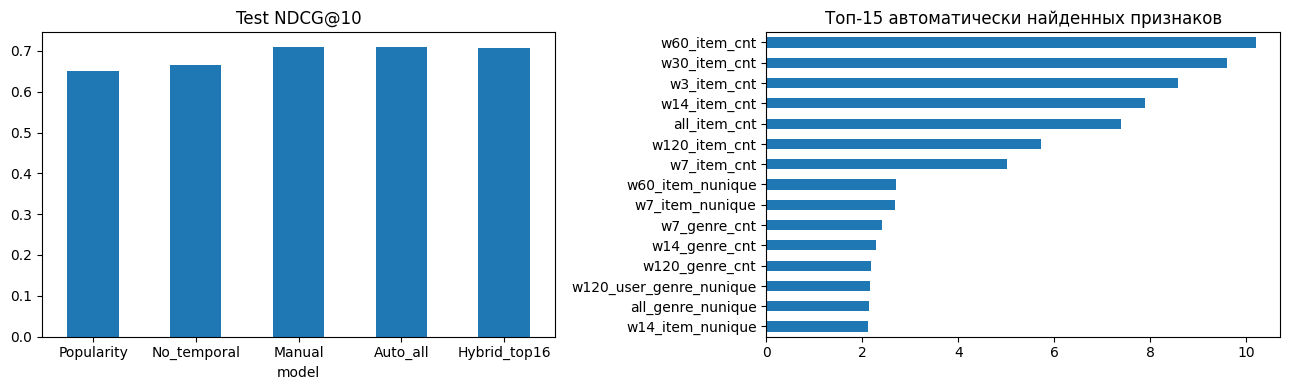

Время расчёта признаков по срезам, сек: [0.74, 1.14, 1.72, 1.87]
Ручной baseline: 17 признаков; Auto: 57 сгенерировано
Выбранные признаки Auto:  ['genre', 'all_user_cnt', 'all_user_nunique', 'all_item_cnt', 'all_item_nunique', 'all_genre_cnt', 'all_genre_nunique', 'all_user_genre_cnt', 'all_user_genre_nunique', 'w3_user_cnt', 'w3_user_nunique', 'w3_item_cnt', 'w3_item_nunique', 'w3_genre_cnt', 'w3_genre_nunique', 'w3_user_genre_cnt', 'w3_user_genre_nunique', 'w7_user_cnt', 'w7_user_nunique', 'w7_item_cnt', 'w7_item_nunique', 'w7_genre_cnt', 'w7_genre_nunique', 'w7_user_genre_cnt', 'w7_user_genre_nunique', 'w14_user_cnt', 'w14_user_nunique', 'w14_item_cnt', 'w14_item_nunique', 'w14_genre_cnt', 'w14_genre_nunique', 'w14_user_genre_cnt', 'w14_user_genre_nunique', 'w30_user_cnt', 'w30_user_nunique', 'w30_item_cnt', 'w30_item_nunique', 'w30_genre_cnt', 'w30_genre_nunique', 'w30_user_genre_cnt', 'w30_user_genre_nunique', 'w60_user_cnt', 'w60_user_nunique', 'w60_item_cnt', 'w60_item_nunique',

In [13]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
final.plot(x='model',y='NDCG@10',kind='bar',ax=axs[0],legend=False,title='Test NDCG@10')
axs[0].tick_params(axis='x',rotation=0)
imp.head(15).iloc[::-1].plot(kind='barh',ax=axs[1],title='Топ-15 автоматически найденных признаков')
plt.tight_layout();plt.savefig(OUT/'results.png',dpi=160);plt.show()
print('Время расчёта признаков по срезам, сек:',[round(c,2) for c in costs])
print('Ручной baseline:',len(manual),'признаков; Auto:',len(auto),'сгенерировано')
print('Выбранные признаки Auto: ',feature_sets[best_auto_name])


## 12. README и выгрузка артефактов
README формируется на основании **реальных** результатов запуска; экспериментальный код и этот ноутбук приложите в репозиторий. Можно скачать метрики, изображение и README одним ZIP.

In [14]:
m=final.set_index('model')
manual_ndcg=float(m.loc['Manual','NDCG@10']); auto_ndcg=float(m.loc[best_auto_name,'NDCG@10'])
change=auto_ndcg-manual_ndcg
readme=f"""# AutoFeatureRec: автоматический поиск признаков для ранжирования KION

## Задача
Сравнить CatBoost с ручными агрегированными признаками и CatBoost с автоматически сгенерированными/отобранными признаками.

## Данные и ограничения
Открытый KION: https://github.com/irsafilo/KION_DATASET. Случайно выбрано {N_USERS} пользователей, сохранены все доступные записи их истории. Набор содержит implicit feedback; отсутствуют логи экспозиций, поэтому отрицательные примеры — не подтверждённые отказы, а неизученные на данный момент объекты. Метрики применимы только к описанному sampled-candidate протоколу. `last_watch_dt` — дата последнего просмотра, не точная полная последовательность событий.

## Эксперимент
Временные срезы: {[(str(a.date()),str(b.date())) for a,b in zip(bounds[:-1],bounds[1:])]}.
Train: первые 2 среза; validation: 3-й; test: 4-й. Для каждого среза используются только взаимодействия до cutoff; целевое событие и будущее не попадают в признаки. Случайный seed {SEED}, {NEG_PER_POS} отрицательных кандидатов на положительный, до {MAX_POS_PER_USER} положительных на пользователя. Каталог кандидатов определяется по предыдущей истории. Важное ограничение: положительные объекты, не встречавшиеся до cutoff в общем каталоге, не оцениваются (cold-start исключён).

Дополнительные контрольные эксперименты: популярность объекта, удаление временных окон, объединение ручных и автоматически выбранных признаков.

Ручные признаки: агрегаты user/item/genre/user-genre и окна {BASE_WINDOWS} дней. Автогенерация: `entity × window × aggregation`, окна {WINDOWS}, агрегаты count и nunique. CatBoostClassifier. Top-K отбирается на train-importance; величина K выбирается по validation NDCG@10; test не влияет на выбор.

## Результаты на test
{final.to_markdown(index=False, floatfmt='.5f')}

Разница NDCG@10 Auto - Manual: {change:+.5f}. Признаков: ручных {len(manual)}, автоматических {len(feature_sets[best_auto_name])} (выбран {best_auto_name}); гибридный набор: {best_hybrid_name}.

## Ограничения и следующие шаги
- Sampled negatives не являются зарегистрированными отрицательными действиями. Обобщение NDCG на весь каталог не гарантируется.
- У KION разреженные истории и агрегированные user-item взаимодействия, что ограничивает качество персональных агрегатов.
- История отдельных выбранных пользователей сохранена полностью, однако глобальная популярность объектов считается внутри пользовательского поднабора.
- Вычислительные затраты растут примерно с числом окон и группировок. Время создания признаков по срезам: {[round(v,2) for v in costs]} сек.
- Для строгой офлайн-проверки полезны дополнительные временные срезы и независимое повторение с другими seed.

## Научные ориентиры
- Kanter & Veeramachaneni (2015), Deep Feature Synthesis: https://www.featuretools.com/
- Horn et al. (2019), autofeat: https://arxiv.org/abs/1901.07329
- Koren (2009), Collaborative Filtering with Temporal Dynamics: https://doi.org/10.1145/1557019.1557072
Метод является собственной ограниченной процедурой перебора агрегатов, а не точным воспроизведением этих работ.

## Воспроизведение
Открыть `AutoFeatureRec_KION.ipynb` в Google Colab, выполнить Runtime → Run all на CPU. Все библиотеки устанавливаются в первой ячейке. Код загружает открытый датасет и создаёт результаты автоматически. Для расширения эксперимента менять N_USERS и NEG_PER_POS.
"""
(OUT/'README.md').write_text(readme,encoding='utf-8')
print(readme[:1700]); print('Сохранено в',OUT)
import shutil
shutil.make_archive('/content/AutoFeatureRec_results','zip',OUT)
print('Архив: /content/AutoFeatureRec_results.zip')

try:
    from google.colab import files as colab_files
    print('Для скачивания архива выполните: colab_files.download("/content/AutoFeatureRec_results.zip")')
except ImportError:
    pass


# AutoFeatureRec: автоматический поиск признаков для ранжирования KION

## Задача
Сравнить CatBoost с ручными агрегированными признаками и CatBoost с автоматически сгенерированными/отобранными признаками.

## Данные и ограничения
Открытый KION: https://github.com/irsafilo/KION_DATASET. Случайно выбрано 15000 пользователей, сохранены все доступные записи их истории. Набор содержит implicit feedback; отсутствуют логи экспозиций, поэтому отрицательные примеры — не подтверждённые отказы, а неизученные на данный момент объекты. Метрики применимы только к описанному sampled-candidate протоколу. `last_watch_dt` — дата последнего просмотра, не точная полная последовательность событий.

## Эксперимент
Временные срезы: [('2021-05-16', '2021-06-10'), ('2021-06-10', '2021-07-04'), ('2021-07-04', '2021-07-28'), ('2021-07-28', '2021-08-22')].
Train: первые 2 среза; validation: 3-й; test: 4-й. Для каждого среза используются только взаимодействия до cutoff; целевое событие и будущее не попадают в приз

### Перед сдачей
1. Выполните все ячейки (Runtime → Run all), убедитесь, что они завершились без ошибки.
2. Сохраните сам ноутбук через **Файл → Скачать → Скачать .ipynb**.
3. Скачайте `/content/AutoFeatureRec_results.zip` из боковой панели Colab (**Файлы**).
4. Добавьте ноутбук, README и таблицы/графики в GitHub или приложите к отчёту.
5. В отчёте отдельно обсудите, как ограничения sampled negatives влияют на выводы. Результат auto может быть хуже ручных признаков — это допустимый результат исследования.

## Проверка независимой выборки и итоговая интерпретация

В этом запуске используется другой seed (123) и, следовательно, другой набор пользователей. Не подбирайте признаки повторно по test. Сравните полученные итоговые значения с первым запуском (seed 42) в отчёте. Сохраните оба CSV, указав seed в именах файлов.

In [15]:
# Зафиксировать seed и результаты для последующего сравнения
replica = final.copy()
replica.insert(0,'seed',SEED)
replica.to_csv(OUT/f'final_metrics_seed{SEED}.csv',index=False)
validation_results.to_csv(OUT/f'validation_metrics_seed{SEED}.csv',index=False)
print('Итоговые результаты независимой выборки:')
display(replica)
print('Сохранено:', OUT)

Итоговые результаты независимой выборки:


,seed,model,num_features,ROC-AUC,LogLoss,NDCG@10
0,123,Popularity,1,0.850671,0.174247,0.651671
1,123,No_temporal,9,0.864392,0.167163,0.666319
2,123,Manual,17,0.876605,0.155850,0.708487
3,123,Auto_all,57,0.877157,0.155479,0.709924
4,123,Hybrid_top16,28,0.876249,0.156129,0.707498


Сохранено: /content/autofeaturerec_results


## Чек-лист требований задания

| Требование | Реализация / ограничение |
|---|---|
| Открытый датасет и полная история выбранных пользователей | KION, сэмплирование по `user_id`, без сэмплирования строк |
| Временной train/validation/test | Срезы 0–1 / 2 / 3; история строго до cutoff |
| Сильный baseline | CatBoost, user/item/genre/user–genre агрегаты |
| Автоматизация признаков | Декартово произведение сущностей × окон × count/nunique; отбор по feature importance |
| Сопоставимые кандидаты | Внутри каждого запуска все модели получают одинаковые пары |
| Метрики | ROC-AUC, LogLoss, NDCG@10 |
| Подбор на validation | Выбор top-K по validation; test после выбора |
| Вычислительные затраты | Время генерации и обучения; анализ feature budget в первом запуске |
| Анализ ограничений | Неэкспонированные negatives, offline candidate sampling, дата последнего просмотра |
| Исследовательская устойчивость | Bootstrap первого запуска и независимый seed 123 |
| Статьи | В отчёт включать только проверенные первоисточники и конкретные подтверждённые утверждения |

**Оставшиеся ограничения:** мало типов агрегаций; не все возможные косвенные связи; отсутствует реальная экспозиция показов и онлайн-оценка; зависимость результатов от схемы negative sampling. Это необходимо честно описать, а не скрывать.

## Дополнительное исследование: нормированные, поведенческие и recency-признаки

Этот эксперимент запускается **после всех предыдущих ячеек**. Новые признаки вычисляются строго из `events.ts < cutoff`. Используются: доля жанра в просмотрах пользователя, сглаженная доля, давность последнего просмотра пользователем/объекта/жанра, агрегаты `total_dur` и `watched_pct` (если доступны). Варианты выбираются только по validation NDCG@10. Test используется один раз для итоговой оценки выбранного варианта.

**Ограничение:** тест текущей выборки уже использовался в основном эксперименте; оценка нового подхода на нём — дополнительный анализ, не новый полностью слепой тест.

In [16]:
# Убедимся, что исходный пайплайн был выполнен
assert all(v in globals() for v in ['events','snapshots','bounds','train','valid','test','manual','auto','fit_model','metrics','OUT'])
print('Колонки событий:',events.columns.tolist())

def extra_features_for_snapshot(candidates, cutoff, events):
    hist=events.loc[events.ts < cutoff].copy()
    assert (hist.ts < cutoff).all()
    out=candidates[['snapshot','user_id','item_id','genre']].copy()
    # User-genre: доля интереса к жанру; Laplace smoothing для редких историй
    ug=hist.groupby(['user_id','genre'],observed=True).size().rename('extra_ug_count').reset_index()
    uc=hist.groupby('user_id').size().rename('extra_user_count').reset_index()
    out=out.merge(ug,on=['user_id','genre'],how='left',validate='many_to_one')
    out=out.merge(uc,on='user_id',how='left',validate='many_to_one')
    out['extra_ug_share']=(out.extra_ug_count.fillna(0)/out.extra_user_count.clip(lower=1))
    out['extra_ug_share_smoothed']=(out.extra_ug_count.fillna(0)+1)/(out.extra_user_count+10)
    out=out.drop(columns=['extra_ug_count','extra_user_count'])
    # Recency: days since last activity; no future records
    for name,keys in [('user',['user_id']),('item',['item_id']),('genre',['genre']),('ug',['user_id','genre'])]:
        last=hist.groupby(keys,observed=True)['ts'].max().rename('_last').reset_index()
        last[f'extra_{name}_recency_days']=(cutoff-last['_last']).dt.total_seconds()/86400
        out=out.merge(last.drop(columns=['_last']),on=keys,how='left',validate='many_to_one')
    # Поведенческие агрегаты по доступным полям исходного KION
    for col in ['total_dur','watched_pct']:
        if col not in hist.columns: continue
        h=hist.copy()
        h[col]=pd.to_numeric(h[col],errors='coerce')
        for name,keys in [('user',['user_id']),('item',['item_id']),('ug',['user_id','genre'])]:
            ag=h.groupby(keys,observed=True)[col].agg(['mean','sum']).reset_index()
            ag=ag.rename(columns={'mean':f'extra_{name}_{col}_mean','sum':f'extra_{name}_{col}_sum'})
            out=out.merge(ag,on=keys,how='left',validate='many_to_one')
    return out.drop(columns=['snapshot','user_id','item_id','genre'])

# Кандидаты и признаки в каждом временном срезе остаются прежними
extra_parts=[]
for sid,(cand,cutoff) in enumerate(zip(snapshots,bounds[:-1])):
    extra=extra_features_for_snapshot(cand,cutoff,events)
    assert len(extra)==len(cand)
    extra_parts.append(extra)
extra_all=pd.concat(extra_parts,ignore_index=True)
assert len(extra_all)==len(all_data)
new_cols=extra_all.columns.tolist()
extra_all=extra_all.replace([np.inf,-np.inf],np.nan).fillna(-1).astype('float32')
augmented=pd.concat([all_data.reset_index(drop=True),extra_all.reset_index(drop=True)],axis=1)
train_plus=augmented[augmented.snapshot.isin([0,1])].copy()
valid_plus=augmented[augmented.snapshot==2].copy()
test_plus=augmented[augmented.snapshot==3].copy()
assert len(train_plus)==len(train) and len(valid_plus)==len(valid) and len(test_plus)==len(test)
print('Добавлено признаков:',len(new_cols),new_cols)


Колонки событий: ['user_id', 'item_id', 'ts', 'genre']
Добавлено признаков: 6 ['extra_ug_share', 'extra_ug_share_smoothed', 'extra_user_recency_days', 'extra_item_recency_days', 'extra_genre_recency_days', 'extra_ug_recency_days']


In [17]:
# Эксперименты с одинаковым CatBoost, train/validation и кандидатами
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, log_loss
import time

families={
 'share':[c for c in new_cols if 'share' in c],
 'recency':[c for c in new_cols if 'recency' in c],
 'behavior':[c for c in new_cols if 'total_dur' in c or 'watched_pct' in c]
}
variants={
 'Manual_original':manual,
 'Manual_plus_share':manual+families['share'],
 'Manual_plus_recency':manual+families['recency'],
 'Manual_plus_behavior':manual+families['behavior'],
 'Manual_plus_all_extra':manual+new_cols,
 'Auto_plus_all_extra':auto+new_cols
}
extra_models={}; extra_rows={}
for name,cols in variants.items():
    cols=list(dict.fromkeys(cols))
    model=CatBoostClassifier(iterations=TRAIN_ITERATIONS,depth=6,learning_rate=.07,loss_function='Logloss',
                             random_seed=SEED,verbose=False,thread_count=2,allow_writing_files=False,l2_leaf_reg=5)
    cats=[c for c in cols if train_plus[c].dtype=='object']
    t0=time.monotonic()
    model.fit(train_plus[cols],train_plus.label,cat_features=cats)
    pred=model.predict_proba(valid_plus[cols])[:,1]
    extra_models[name]=model
    extra_rows[name]={'model':name,'n_features':len(cols),'fit_seconds':time.monotonic()-t0,**metrics(valid_plus,pred)}
extra_validation=pd.DataFrame(extra_rows.values()).sort_values('NDCG@10',ascending=False)
display(extra_validation)
extra_validation.to_csv(OUT/f'expanded_features_validation_seed{SEED}.csv',index=False)


,model,n_features,fit_seconds,ROC-AUC,LogLoss,NDCG@10
5,Auto_plus_all_extra,63,25.607463,0.879358,0.149707,0.732363
4,Manual_plus_all_extra,23,21.585929,0.876977,0.150970,0.730429
2,Manual_plus_recency,21,22.303154,0.877234,0.150795,0.730323
0,Manual_original,17,20.992377,0.876367,0.151043,0.730300
3,Manual_plus_behavior,17,21.723030,0.876367,0.151043,0.730300
1,Manual_plus_share,19,20.923804,0.875707,0.151223,0.728395


In [18]:
# Фиксируем выбор по validation до просмотра test
best_name=extra_validation.iloc[0]['model']
comparison_names=list(dict.fromkeys(['Manual_original',best_name]))
extra_test_rows=[]
for name in comparison_names:
    cols=variants[name]
    pred=extra_models[name].predict_proba(test_plus[cols])[:,1]
    extra_test_rows.append({'model':name,'seed':SEED,'n_features':len(cols),**metrics(test_plus,pred)})
extra_test=pd.DataFrame(extra_test_rows)
display(extra_test)
extra_test.to_csv(OUT/f'expanded_features_test_seed{SEED}.csv',index=False)
print('Победитель на validation:',best_name)
print('Важно: test на этом seed ранее уже анализировался. Это exploratory-результат.')


,model,seed,n_features,ROC-AUC,LogLoss,NDCG@10
0,Manual_original,123,17,0.876605,0.155850,0.708487
1,Auto_plus_all_extra,123,63,0.875952,0.156208,0.707615


Победитель на validation: Auto_plus_all_extra
Важно: test на этом seed ранее уже анализировался. Это exploratory-результат.
